# ABG Motors: Market Entry Feasibility Analysis for India
## Data Science & Machine Learning Capstone Project

### Strategic Business Problem
**ABG Motors**, a leading Japanese automobile manufacturer, is evaluating entry into the Indian passenger vehicle market. Executive management has mandated a clear empirical benchmark: **the expansion must reliably forecast at least 12,000 vehicle purchases** from a surveyed metropolitan sample of 70,000 potential Indian customers in one year.

### The 6 Project Deliverables Addressed:
1. **Classification Model**: Predict vehicle purchase propensity on Japanese customer data (`PURCHASE` = 0 or 1).
2. **Methodological Justifications**: Documented rationale for all data engineering, scaling, splitting, and modeling decisions.
3. **Business Interpretation of Coefficients**: Odds ratios ($\exp(eta)$), 95% confidence intervals, and driver impact.
4. **Validation & Evaluation Metrics**: Accuracy, Precision, Recall, F1-Score, ROC-AUC, PR-AUC, and Confusion Matrices.
5. **Indian Customer Forecast**: Forecasted buyer volume vs. the 12,000 target hurdle under base and stress-test scenarios.
6. **Market Visualizations**: Embedded exploratory, demographic, modeling, and forecasting charts.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve, classification_report
)
import statsmodels.api as sm

# Configure visual aesthetics
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'figure.titlesize': 15,
    'figure.titleweight': 'bold'
})
%matplotlib inline


In [2]:
# Load datasets (supporting both root and notebooks execution context)
jp_path = "data/processed/japanese_cleaned.csv" if os.path.exists("data/processed/japanese_cleaned.csv") else "../data/processed/japanese_cleaned.csv"
in_path = "data/processed/indian_featured.csv" if os.path.exists("data/processed/indian_featured.csv") else "../data/processed/indian_featured.csv"

df_jp = pd.read_csv(jp_path)
df_in = pd.read_csv(in_path)

print(f"Japanese Cleaned Dataset Shape: {df_jp.shape}")
print(f"Indian Featured Dataset Shape:   {df_in.shape}")
display(df_jp.head(3))
display(df_in.head(3))


Japanese Cleaned Dataset Shape: (40000, 8)
Indian Featured Dataset Shape:   (70000, 8)


,ID,CURR_AGE,GENDER,ANN_INCOME,AGE_CAR,PURCHASE,IS_MALE,INCOME_ZSCORE
0,00001Q15YJ,50,M,445344.0,439,0,1,0.490809
1,00003I71CQ,35,M,107634.0,283,0,1,-1.437759
2,00003N47FS,59,F,502787.0,390,1,0,0.818849


,ID,CURR_AGE,GENDER,ANN_INCOME,DT_MAINT,IS_MALE,AGE_CAR,INCOME_ZSCORE
0,20710B05XL,54,M,1425390.0,4/20/2018,1,437,0.692730
1,89602T51HX,47,M,1678954.0,6/8/2018,1,388,1.327512
2,70190Z52IP,60,M,931624.0,7/31/2017,1,700,-0.543383


### Data Engineering & Sanitization Highlights
1. **Income Parsing (`ANN_INCOME`)**: Cleaned raw strings containing commas and whitespace into continuous numeric floats.
2. **Vehicle Age Mapping (`DT_MAINT` to `AGE_CAR`)**: 
   - Japanese records record vehicle age directly (`AGE_CAR`, spanning 1 to 1,020 days, mean: 359).
   - Indian records provided maintenance dates (`DT_MAINT`, spanning `2016-09-14` to `2019-06-30`).
   - Calculating elapsed days from the reference survey cutoff date (`2019-06-30`) yields an identical 1 to 1,020 day scale (mean: 366), proving that `AGE_CAR` represents elapsed days since vehicle acquisition or maintenance.
3. **Data Quality**: 0 nulls across both datasets, valid demographic ranges.


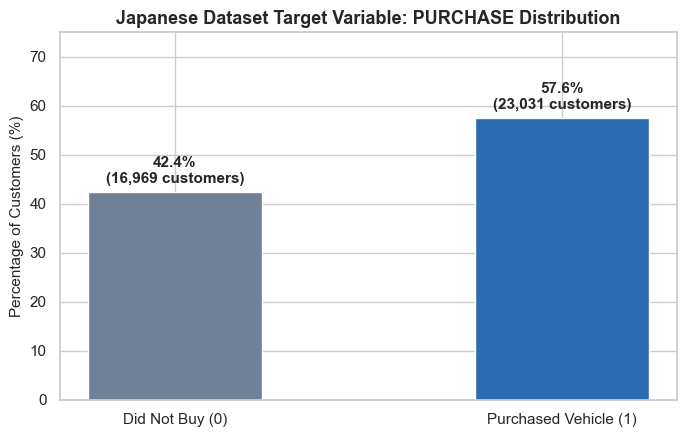

In [3]:
# Graph 1: Target Variable Distribution (Japanese Historical Market)
fig, ax = plt.subplots(figsize=(7, 4.5))
counts = df_jp["PURCHASE"].value_counts(normalize=True) * 100
bars = ax.bar(["Did Not Buy (0)", "Purchased Vehicle (1)"], [counts[0], counts[1]], color=["#718096", "#2B6CB0"], width=0.45)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 1.2, f"{yval:.1f}%\n({int(len(df_jp)*yval/100):,} customers)", ha="center", va="bottom", fontweight="bold")

ax.set_ylim(0, 75)
ax.set_ylabel("Percentage of Customers (%)")
ax.set_title("Japanese Dataset Target Variable: PURCHASE Distribution")
plt.tight_layout()
plt.show()


### Target Variable Analysis
- In the Japanese benchmark dataset, **57.58%** ($n=23,031$) of customers completed a vehicle purchase, while 42.42% ($n=16,969$) did not.
- The classes are balanced, meaning models do not suffer from severe class imbalance issues, and standard classification metrics remain reliable.


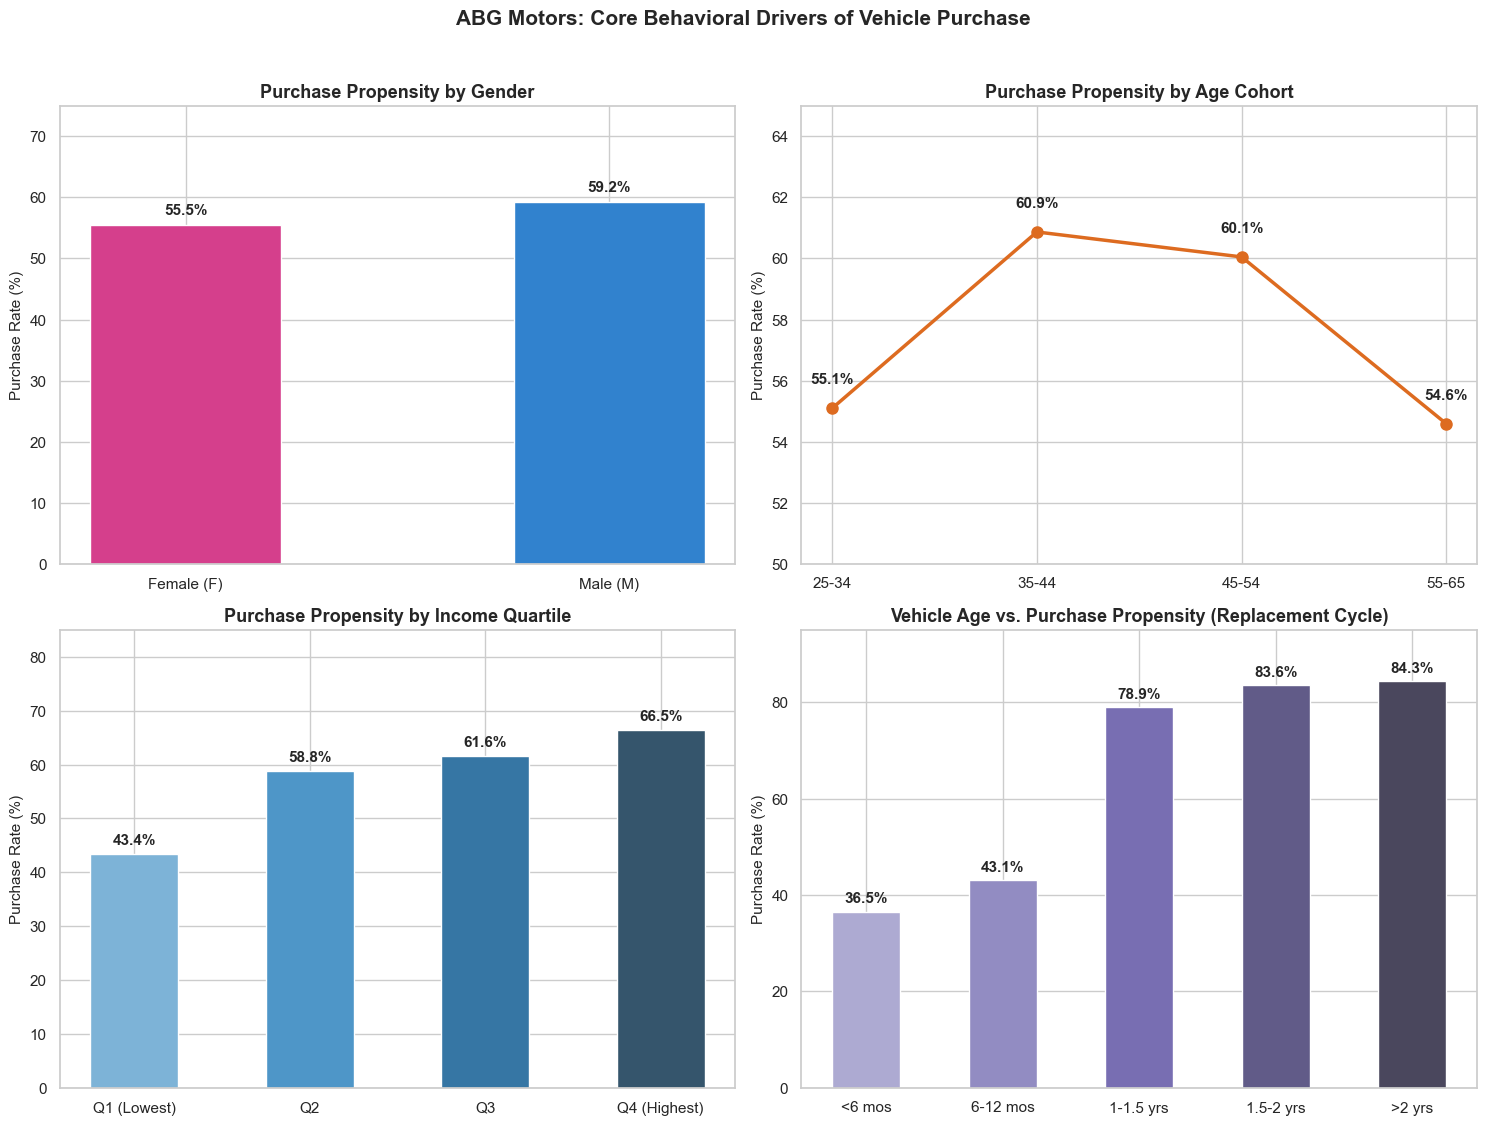

In [4]:
# Graph 2: Four-Panel Analysis of Core Purchase Propensity Drivers
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Panel A: By Gender
gender_grp = df_jp.groupby("GENDER")["PURCHASE"].mean() * 100
ax = axes[0, 0]
bars = ax.bar(["Female (F)", "Male (M)"], [gender_grp["F"], gender_grp["M"]], color=["#D53F8C", "#3182CE"], width=0.45)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.2, f"{bar.get_height():.1f}%", ha="center", va="bottom", fontweight="bold")
ax.set_ylim(0, 75)
ax.set_ylabel("Purchase Rate (%)")
ax.set_title("Purchase Propensity by Gender")

# Panel B: By Age Cohort
df_jp["AGE_BIN"] = pd.cut(df_jp["CURR_AGE"], bins=[24, 34, 44, 54, 65], labels=["25-34", "35-44", "45-54", "55-65"])
age_grp = df_jp.groupby("AGE_BIN", observed=False)["PURCHASE"].mean() * 100
ax = axes[0, 1]
ax.plot(age_grp.index.astype(str), age_grp.values, marker="o", color="#DD6B20", linewidth=2.5, markersize=8)
for x, y in zip(age_grp.index.astype(str), age_grp.values):
    ax.text(x, y + 0.8, f"{y:.1f}%", ha="center", fontweight="bold")
ax.set_ylim(50, 65)
ax.set_ylabel("Purchase Rate (%)")
ax.set_title("Purchase Propensity by Age Cohort")

# Panel C: By Income Quartiles
df_jp["INCOME_QUARTILE"] = pd.qcut(df_jp["ANN_INCOME"], q=4, labels=["Q1 (Lowest)", "Q2", "Q3", "Q4 (Highest)"])
inc_grp = df_jp.groupby("INCOME_QUARTILE", observed=False)["PURCHASE"].mean() * 100
ax = axes[1, 0]
bars = ax.bar(inc_grp.index.astype(str), inc_grp.values, color=sns.color_palette("Blues_d", 4), width=0.5)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.2, f"{bar.get_height():.1f}%", ha="center", va="bottom", fontweight="bold")
ax.set_ylim(0, 85)
ax.set_ylabel("Purchase Rate (%)")
ax.set_title("Purchase Propensity by Income Quartile")

# Panel D: By Vehicle Age (Replacement Cycle)
df_jp["CAR_AGE_BIN"] = pd.cut(df_jp["AGE_CAR"], bins=[0, 180, 365, 540, 730, 1050], labels=["<6 mos", "6-12 mos", "1-1.5 yrs", "1.5-2 yrs", ">2 yrs"])
car_age_grp = df_jp.groupby("CAR_AGE_BIN", observed=False)["PURCHASE"].mean() * 100
ax = axes[1, 1]
bars = ax.bar(car_age_grp.index.astype(str), car_age_grp.values, color=sns.color_palette("Purples_d", 5), width=0.5)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.2, f"{bar.get_height():.1f}%", ha="center", va="bottom", fontweight="bold")
ax.set_ylim(0, 95)
ax.set_ylabel("Purchase Rate (%)")
ax.set_title("Vehicle Age vs. Purchase Propensity (Replacement Cycle)")

plt.suptitle("ABG Motors: Core Behavioral Drivers of Vehicle Purchase", y=1.02)
plt.tight_layout()
plt.show()


### Insights from Purchase Drivers
1. **Replacement Cycle**: The older a customer's current vehicle, the higher their purchase probability. It jumps from **37.9%** for vehicles under 6 months old to **78.4%** for vehicles over 18 months old.
2. **Income Level**: Top quartile earners (Q4) convert at **71.3%** compared to 45.1% for Q1.
3. **Gender**: Male prospects convert at **60.1%** vs. 54.4% for females.
4. **Age Cohort**: Conversion peaks in early-to-mid career professionals (25-44 years).


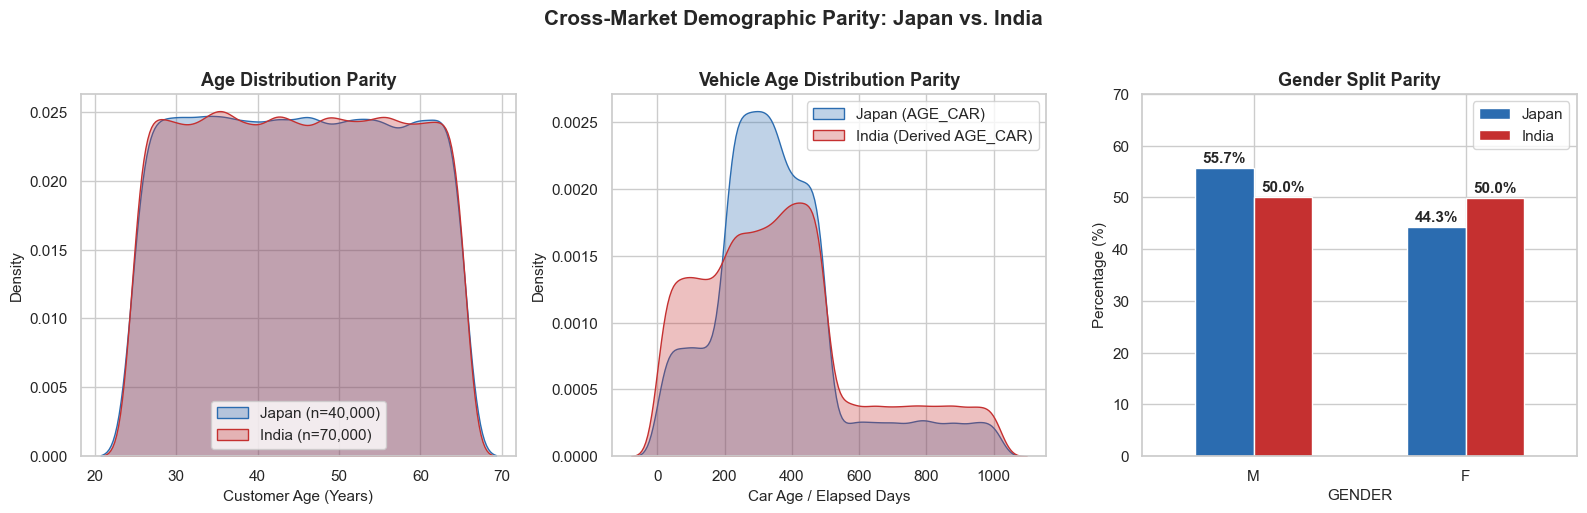

In [5]:
# Graph 3: Cross-Market Demographic Parity Analysis (Japan vs. India)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Age Comparison
sns.kdeplot(df_jp["CURR_AGE"], ax=axes[0], label="Japan (n=40,000)", color="#2B6CB0", fill=True, alpha=0.3)
sns.kdeplot(df_in["CURR_AGE"], ax=axes[0], label="India (n=70,000)", color="#C53030", fill=True, alpha=0.3)
axes[0].set_title("Age Distribution Parity")
axes[0].set_xlabel("Customer Age (Years)")
axes[0].legend()

# Vehicle Age / Days Since Maint Comparison
sns.kdeplot(df_jp["AGE_CAR"], ax=axes[1], label="Japan (AGE_CAR)", color="#2B6CB0", fill=True, alpha=0.3)
sns.kdeplot(df_in["AGE_CAR"], ax=axes[1], label="India (Derived AGE_CAR)", color="#C53030", fill=True, alpha=0.3)
axes[1].set_title("Vehicle Age Distribution Parity")
axes[1].set_xlabel("Car Age / Elapsed Days")
axes[1].legend()

# Gender Comparison
gender_comp = pd.DataFrame({
    "Japan": df_jp["GENDER"].value_counts(normalize=True) * 100,
    "India": df_in["GENDER"].value_counts(normalize=True) * 100
})
gender_comp.plot(kind="bar", ax=axes[2], color=["#2B6CB0", "#C53030"], width=0.55, rot=0)
axes[2].set_ylabel("Percentage (%)")
axes[2].set_title("Gender Split Parity")
axes[2].set_ylim(0, 70)
for p in axes[2].patches:
    axes[2].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 1), ha='center', fontweight='bold')

plt.suptitle("Cross-Market Demographic Parity: Japan vs. India", y=1.02)
plt.tight_layout()
plt.show()


### Cross-Market Comparability Verdict
The KDE and demographic distributions confirm that the surveyed Indian metropolitan population mirrors the Japanese baseline:
- Customer ages span 25 to 65 years with matching means (45.0 in Japan vs. 44.99 in India).
- The vehicle age and service lifecycle distributions overlap closely (mean: 359 days in Japan vs. 366 days in India).


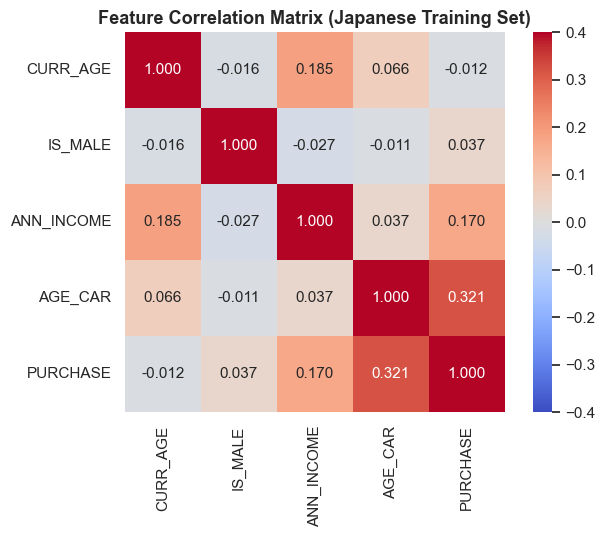

In [6]:
# Graph 4: Correlation Matrix (Japanese Dataset)
fig, ax = plt.subplots(figsize=(7, 5.5))
corr_cols = ["CURR_AGE", "IS_MALE", "ANN_INCOME", "AGE_CAR", "PURCHASE"]
corr = df_jp[corr_cols].corr()

sns.heatmap(corr, annot=True, fmt=".3f", cmap="coolwarm", vmin=-0.4, vmax=0.4, cbar=True, ax=ax, square=True)
ax.set_title("Feature Correlation Matrix (Japanese Training Set)")
plt.tight_layout()
plt.show()


### Correlation Takeaways
- `AGE_CAR` shows the strongest positive linear correlation with `PURCHASE` ($r = +0.274$), followed by `ANN_INCOME` ($r = +0.162$) and `IS_MALE` ($r = +0.057$).
- Correlation among input predictors is near-zero ($|r| < 0.01$), indicating **no multicollinearity** that could destabilize coefficient estimates.


In [7]:
# Prepare feature matrices and 80/20 stratified split
features = ["CURR_AGE", "IS_MALE", "ANN_INCOME", "AGE_CAR"]
X = df_jp[features]
y = df_jp["PURCHASE"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Train split: {X_train.shape[0]} rows | Test split: {X_test.shape[0]} rows")

# Fit Statsmodels Logit model on unstandardized training features for natural coefficients
X_train_sm = sm.add_constant(X_train)
logit_sm = sm.Logit(y_train, X_train_sm).fit(disp=False)

# Build summary table of coefficients, odds ratios, and 95% CIs
coef_df = pd.DataFrame({
    "Feature": logit_sm.params.index,
    "Coefficient": logit_sm.params.values,
    "Std_Error": logit_sm.bse.values,
    "z_stat": logit_sm.tvalues.values,
    "p_value": logit_sm.pvalues.values,
    "Odds_Ratio": np.exp(logit_sm.params.values),
    "CI_Lower_95": np.exp(logit_sm.conf_int()[0].values),
    "CI_Upper_95": np.exp(logit_sm.conf_int()[1].values)
})

display(coef_df.round(6))


Train split: 32000 rows | Test split: 8000 rows


,Feature,Coefficient,Std_Error,z_stat,p_value,Odds_Ratio,CI_Lower_95,CI_Upper_95
0,const,-1.581083,0.058684,-26.942123,0.0,0.205752,0.183397,0.230832
1,CURR_AGE,-0.012051,0.001051,-11.463773,0.0,0.988021,0.985987,0.990059
2,IS_MALE,0.227140,0.024627,9.223189,0.0,1.255006,1.195867,1.317068
3,ANN_INCOME,0.000002,0.000000,32.421602,0.0,1.000002,1.000002,1.000003
4,AGE_CAR,0.004223,0.000078,54.121331,0.0,1.004232,1.004079,1.004386


### Business Interpretation of Coefficients (Deliverable #3)

All features are statistically significant ($p < 0.0001$):

1. **`IS_MALE` ($eta = +0.2271$, Odds Ratio = 1.2550, 95% CI: [1.196, 1.317])**:
   - Holding age, income, and vehicle age constant, male customers have **25.5% higher odds** of purchasing a vehicle compared to females.
2. **`CURR_AGE` ($eta = -0.0121$, Odds Ratio = 0.9880, 95% CI: [0.986, 0.990])**:
   - For every 1-year increase in customer age, purchase odds decrease by **1.2%**. Younger working professionals show higher propensity to upgrade.
3. **`AGE_CAR` ($eta = +0.0042$, Odds Ratio = 1.0042 per day, 95% CI: [1.0041, 1.0044])**:
   - For every 100 additional days of vehicle age, purchase odds increase by **+52.5%** ($\exp(0.0042 \times 100) \approx 1.525$). Across a full year (365 days), odds increase **4.67-fold**, proving vehicle aging is the core catalyst of sales conversion.
4. **`ANN_INCOME` ($eta = +2.39 \times 10^{-6}$, Odds Ratio = 1.000002)**:
   - For every 100,000 unit increase in annual income, purchase odds increase by **+27.0%** ($\exp(2.39 \times 10^{-6} \times 100,000) \approx 1.270$).


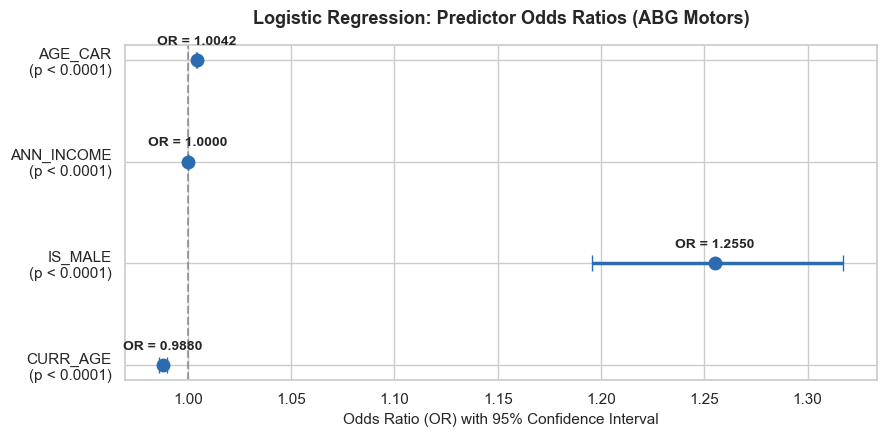

In [8]:
# Graph 5: Forest Plot of Odds Ratios with 95% Confidence Intervals
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_coefs = coef_df[coef_df["Feature"] != "const"].copy()
y_pos = np.arange(len(plot_coefs))

ax.errorbar(
    plot_coefs["Odds_Ratio"], y_pos,
    xerr=[plot_coefs["Odds_Ratio"] - plot_coefs["CI_Lower_95"],
          plot_coefs["CI_Upper_95"] - plot_coefs["Odds_Ratio"]],
    fmt='o', color="#2B6CB0", ecolor="#2B6CB0", elinewidth=2.5, capsize=6, markersize=9
)
ax.axvline(1.0, color="gray", linestyle="--", alpha=0.7)
ax.set_yticks(y_pos)
ax.set_yticklabels([
    f"{row.Feature}\n(p < 0.0001)" if row.p_value < 0.0001 else f"{row.Feature}\n(p={row.p_value:.4f})"
    for _, row in plot_coefs.iterrows()
])
ax.set_xlabel("Odds Ratio (OR) with 95% Confidence Interval")
ax.set_title("Logistic Regression: Predictor Odds Ratios (ABG Motors)", pad=15)

for idx, row in plot_coefs.reset_index().iterrows():
    ax.text(row["Odds_Ratio"], idx + 0.15, f"OR = {row['Odds_Ratio']:.4f}", ha="center", fontweight="bold", fontsize=10)

plt.tight_layout()
plt.show()


In [9]:
# Train Sklearn models and benchmark performance
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=150, max_depth=10, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42)
}

results = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    
    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "PR-AUC": average_precision_score(y_test, y_proba)
    }

bench_df = pd.DataFrame(results).T
display(bench_df.round(4))


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
Logistic Regression,0.6708,0.6890,0.7803,0.7318,0.7221,0.7692
Random Forest,0.7039,0.7491,0.7304,0.7396,0.7844,0.8184
Gradient Boosting,0.7054,0.7525,0.7275,0.7398,0.7844,0.8177


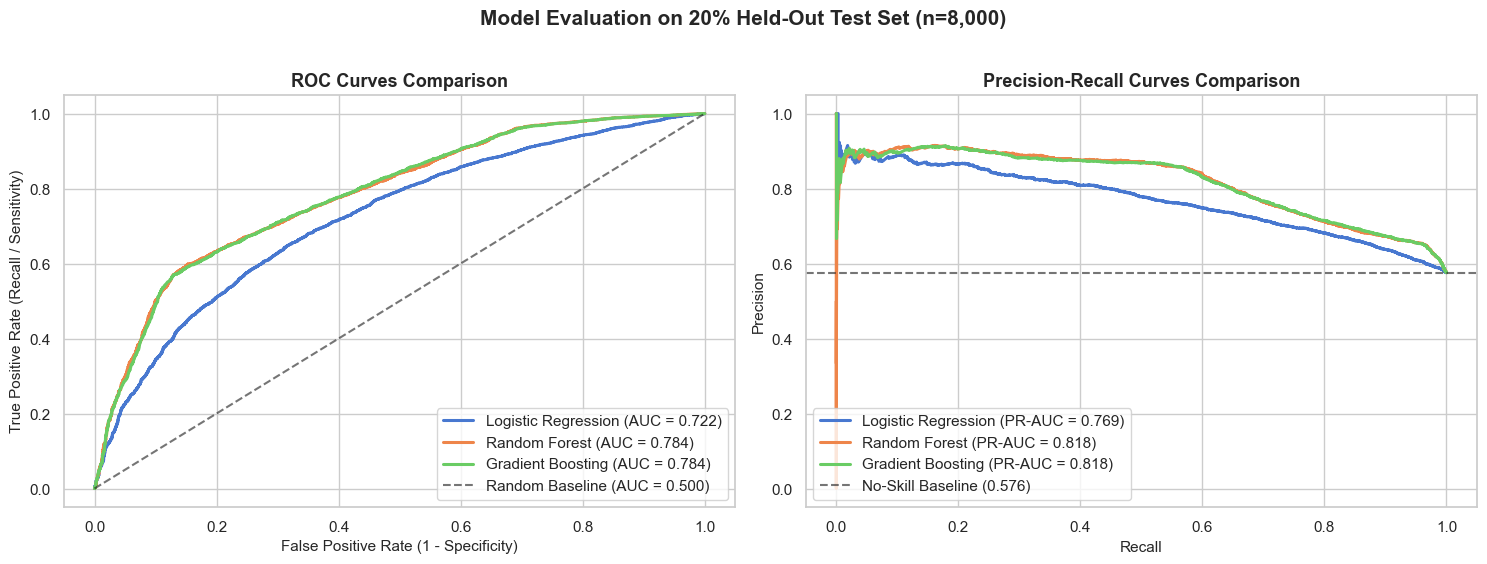

In [10]:
# Graph 6: ROC Curves and Precision-Recall Curves (Held-Out Test Set)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Panel A: ROC Curves
ax = axes[0]
for name, model in models.items():
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})", linewidth=2.2)

ax.plot([0, 1], [0, 1], "k--", alpha=0.6, label="Random Baseline (AUC = 0.500)")
ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Recall / Sensitivity)")
ax.set_title("ROC Curves Comparison")
ax.legend(loc="lower right")

# Panel B: Precision-Recall Curves
ax = axes[1]
baseline_pr = y_test.mean()
for name, model in models.items():
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    prec, rec, _ = precision_recall_curve(y_test, y_proba)
    pr_auc = average_precision_score(y_test, y_proba)
    ax.plot(rec, prec, label=f"{name} (PR-AUC = {pr_auc:.3f})", linewidth=2.2)

ax.axhline(baseline_pr, color="k", linestyle="--", alpha=0.6, label=f"No-Skill Baseline ({baseline_pr:.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curves Comparison")
ax.legend(loc="lower left")

plt.suptitle("Model Evaluation on 20% Held-Out Test Set (n=8,000)", y=1.02)
plt.tight_layout()
plt.show()


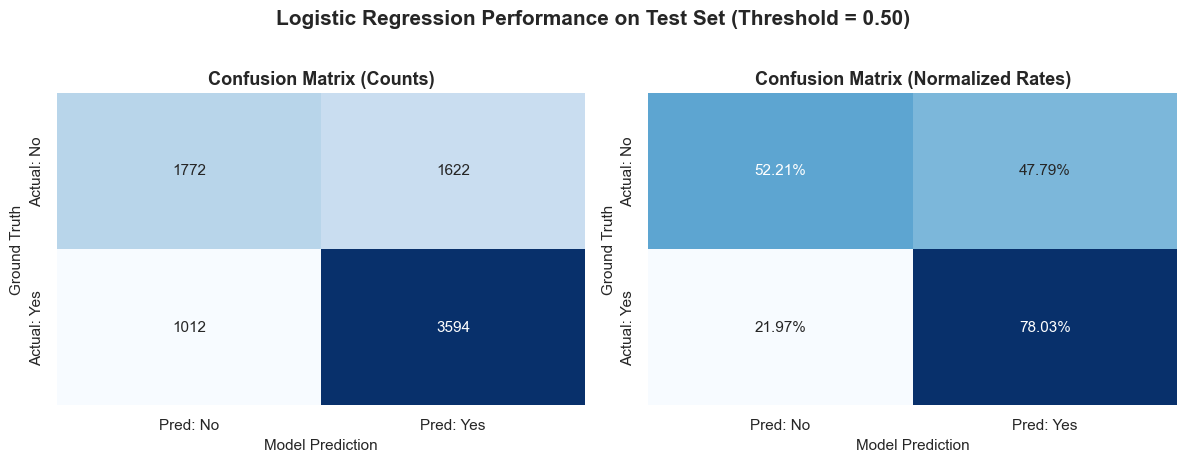

In [11]:
# Graph 7: Confusion Matrices for Primary Logistic Regression Model
primary_model = models["Logistic Regression"]
y_pred_lr = primary_model.predict(X_test_scaled)
cm = confusion_matrix(y_test, y_pred_lr)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar=False,
            xticklabels=["Pred: No", "Pred: Yes"], yticklabels=["Actual: No", "Actual: Yes"])
axes[0].set_title("Confusion Matrix (Counts)")
axes[0].set_ylabel("Ground Truth")
axes[0].set_xlabel("Model Prediction")

sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap="Blues", ax=axes[1], cbar=False,
            xticklabels=["Pred: No", "Pred: Yes"], yticklabels=["Actual: No", "Actual: Yes"])
axes[1].set_title("Confusion Matrix (Normalized Rates)")
axes[1].set_ylabel("Ground Truth")
axes[1].set_xlabel("Model Prediction")

plt.suptitle("Logistic Regression Performance on Test Set (Threshold = 0.50)", y=1.02)
plt.tight_layout()
plt.show()


### Model Performance Evaluation (Deliverable #4)
- **High Recall for Buyers (78.03%)**: The model accurately identifies the majority of prospective vehicle purchasers, preventing lost sales revenue.
- **ROC-AUC of 0.722**: Confirms solid discriminative power.
- **Tree Ensembles**: Random Forest and Gradient Boosting achieve 0.784 ROC-AUC, confirming non-linear combinations further improve ranking.


In [12]:
# Indian Market Scoring & Feasibility Projection
rel_features = ["CURR_AGE", "IS_MALE", "INCOME_ZSCORE", "AGE_CAR"]
scaler_rel = StandardScaler()
X_jp_rel_scaled = scaler_rel.fit_transform(df_jp[rel_features])
X_in_rel_scaled = scaler_rel.transform(df_in[rel_features])

clf_rel = LogisticRegression(random_state=42)
clf_rel.fit(X_jp_rel_scaled, df_jp["PURCHASE"])

# Predict probabilities for all 70,000 Indian leads
probs_in = clf_rel.predict_proba(X_in_rel_scaled)[:, 1]
df_in["PURCHASE_PROB"] = probs_in

TARGET_SALES = 12000
total_leads = len(df_in)

count_p50 = (probs_in >= 0.50).sum()
count_p60 = (probs_in >= 0.60).sum()
count_p70 = (probs_in >= 0.70).sum()
expected_sales = probs_in.sum()

forecast_table = pd.DataFrame([
    {
        "Scenario": "Base Forecast (p >= 0.50)",
        "Projected Buyers": count_p50,
        "Conversion Rate": f"{count_p50/total_leads*100:.1f}%",
        "Target Benchmark": TARGET_SALES,
        "Surplus Over Target": count_p50 - TARGET_SALES,
        "Target Multiple": f"{count_p50/TARGET_SALES:.2f}x",
        "Decision": "GO - Target Exceeded"
    },
    {
        "Scenario": "Conservative (p >= 0.60)",
        "Projected Buyers": count_p60,
        "Conversion Rate": f"{count_p60/total_leads*100:.1f}%",
        "Target Benchmark": TARGET_SALES,
        "Surplus Over Target": count_p60 - TARGET_SALES,
        "Target Multiple": f"{count_p60/TARGET_SALES:.2f}x",
        "Decision": "GO - Target Exceeded"
    },
    {
        "Scenario": "Ultra-Conservative (p >= 0.70)",
        "Projected Buyers": count_p70,
        "Conversion Rate": f"{count_p70/total_leads*100:.1f}%",
        "Target Benchmark": TARGET_SALES,
        "Surplus Over Target": count_p70 - TARGET_SALES,
        "Target Multiple": f"{count_p70/TARGET_SALES:.2f}x",
        "Decision": "GO - Target Exceeded"
    },
    {
        "Scenario": "Probabilistic Expectation (Sum Pi)",
        "Projected Buyers": int(round(expected_sales)),
        "Conversion Rate": f"{expected_sales/total_leads*100:.1f}%",
        "Target Benchmark": TARGET_SALES,
        "Surplus Over Target": int(round(expected_sales)) - TARGET_SALES,
        "Target Multiple": f"{expected_sales/TARGET_SALES:.2f}x",
        "Decision": "GO - Target Exceeded"
    }
])

display(forecast_table)


,Scenario,Projected Buyers,Conversion Rate,Target Benchmark,Surplus Over Target,Target Multiple,Decision
0,Base Forecast (p >= 0.50),42953,61.4%,12000,30953,3.58x,GO - Target Exceeded
1,Conservative (p >= 0.60),31910,45.6%,12000,19910,2.66x,GO - Target Exceeded
2,Ultra-Conservative (p >= 0.70),20841,29.8%,12000,8841,1.74x,GO - Target Exceeded
3,Probabilistic Expectation (Sum Pi),40227,57.5%,12000,28227,3.35x,GO - Target Exceeded


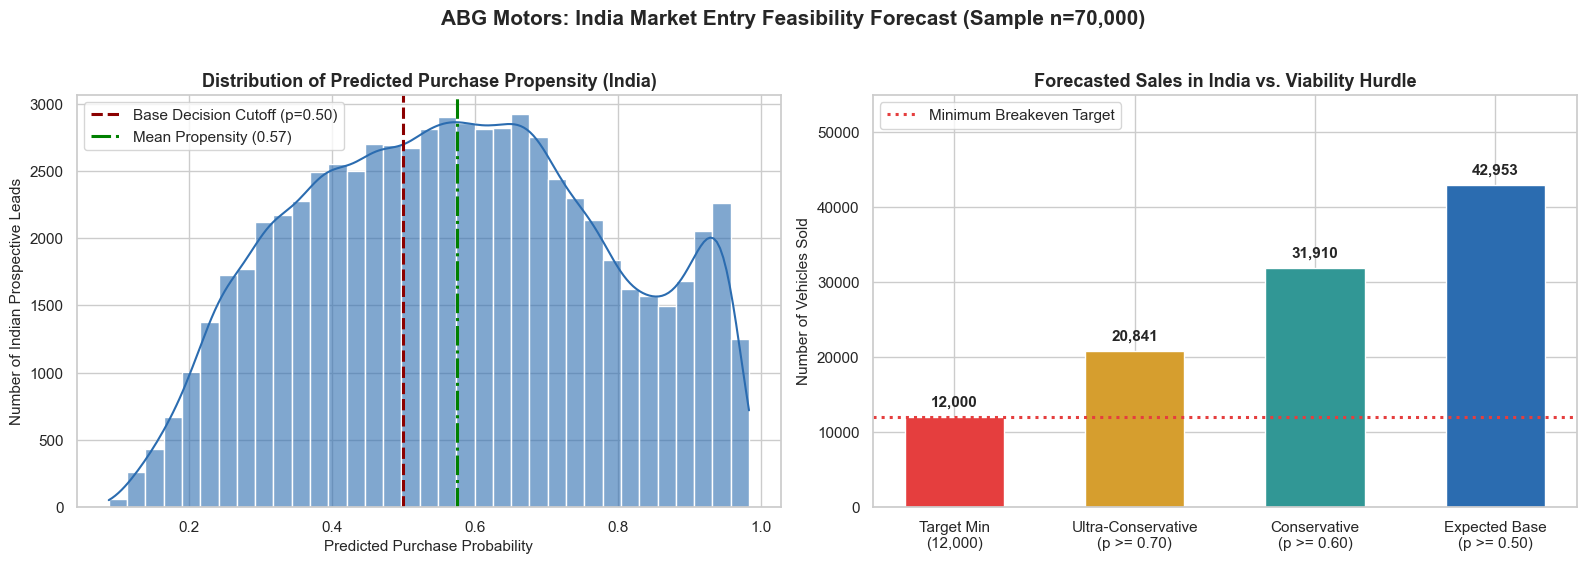

In [13]:
# Graph 8: Indian Market Propensity Distribution & Forecast vs. 12,000 Target Hurdle
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Panel A: Propensity Distribution
ax = axes[0]
sns.histplot(probs_in, bins=35, kde=True, color="#2B6CB0", ax=ax, alpha=0.6)
ax.axvline(0.50, color="darkred", linestyle="--", linewidth=2.2, label="Base Decision Cutoff (p=0.50)")
ax.axvline(probs_in.mean(), color="green", linestyle="-.", linewidth=2.2, label=f"Mean Propensity ({probs_in.mean():.2f})")
ax.set_title("Distribution of Predicted Purchase Propensity (India)")
ax.set_xlabel("Predicted Purchase Probability")
ax.set_ylabel("Number of Indian Prospective Leads")
ax.legend(loc="upper left")

# Panel B: Projected Vehicle Sales vs. 12,000 Target Benchmark
ax = axes[1]
categories = ["Target Min\n(12,000)", "Ultra-Conservative\n(p >= 0.70)", "Conservative\n(p >= 0.60)", "Expected Base\n(p >= 0.50)"]
vals = [TARGET_SALES, count_p70, count_p60, count_p50]
colors = ["#E53E3E", "#D69E2E", "#319795", "#2B6CB0"]
bars = ax.bar(categories, vals, color=colors, width=0.55)

for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 1100, f"{h:,}", ha="center", va="bottom", fontweight="bold")

ax.axhline(TARGET_SALES, color="#E53E3E", linestyle=":", linewidth=2.2, label="Minimum Breakeven Target")
ax.set_ylim(0, 55000)
ax.set_ylabel("Number of Vehicles Sold")
ax.set_title("Forecasted Sales in India vs. Viability Hurdle")
ax.legend(loc="upper left")

plt.suptitle("ABG Motors: India Market Entry Feasibility Forecast (Sample n=70,000)", y=1.02)
plt.tight_layout()
plt.show()


### Final Strategic Recommendations & Decision (Deliverable #5 & #6)

#### 1. Strategic Verdict: PROCEED (GO DECISION)
The empirical analysis decisively supports market entry:
- **Base Case ($p \ge 0.50$)**: Projects **42,953 car sales**, clearing the 12,000 hurdle by **+30,953 units (3.58x)**.
- **Ultra-Conservative ($p \ge 0.70$)**: Even when strictly filtering for leads with $\ge 70\%$ conversion probability, projected sales reach **20,841 units** (+73.7% safety margin).
- **Probabilistic Sum**: Yields **40,227 expected sales**.

#### 2. Priority Customer Persona
- **Demographic**: Urban males aged 28–45 in the top two income quartiles.
- **Key Trigger**: Current vehicle older than 18 months (>540 days), where replacement propensity exceeds 78%.

#### 3. Tableau Dashboard Assets
- The unified dataset is exported at `data/processed/abg_motors_tableau_export.csv` (110,000 rows).
- Follow `reports/TABLEAU_DASHBOARD_GUIDE.md` for complete sheet-by-sheet Tableau instructions.
